# k-Nearest Neighbours and Model Evaluation

The theory is in [README.md](./README.md) — the algorithm, distance metrics, the curse of
dimensionality, cross-validation and the metrics. This notebook is one worked example.

The dataset is **wine**: 178 bottles, thirteen chemical measurements each, three cultivars. One
question runs through the whole notebook — *how good is this classifier?* — and most of the work
goes into showing how many ways there are to answer it wrongly.

A note on what this notebook does not do. Everything here uses library implementations, because
the subject is what the numbers mean rather than how to compute them. The one exception is the
kd-tree, built from scratch because the library hides exactly the part worth seeing. Your homework is the
opposite: build kNN, the normalisation, the stratified split and the 10-fold cross-validation
yourself, on a different dataset. So read this for the reasoning, not for code to copy.

## Setup

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (confusion_matrix, classification_report,
                             precision_recall_fscore_support)

rng = np.random.default_rng(0)

## The data

Thirteen measurements taken from a chemical analysis of wines grown in the same region of Italy by
three different cultivators. The task is to recover the cultivar from the chemistry.

The column to watch is the last one.

In [2]:
wine = load_wine()
X, y = wine.data, wine.target

print(f"{X.shape[0]} bottles, {X.shape[1]} measurements, {len(wine.target_names)} cultivars")
print(f"class sizes: {np.bincount(y)}\n")

print(f"{'measurement':<32}{'min':>9}{'max':>9}{'std':>9}")
for name, column in zip(wine.feature_names, X.T):
    print(f"{name:<32}{column.min():>9.2f}{column.max():>9.2f}{column.std():>9.2f}")

spread = X.std(axis=0)
widest, narrowest = spread.argmax(), spread.argmin()
print(f"\n{wine.feature_names[widest]} varies {spread[widest] / spread[narrowest]:.0f}x more "
      f"than {wine.feature_names[narrowest]}")

178 bottles, 13 measurements, 3 cultivars
class sizes: [59 71 48]

measurement                           min      max      std
alcohol                             11.03    14.83     0.81
malic_acid                           0.74     5.80     1.11
ash                                  1.36     3.23     0.27
alcalinity_of_ash                   10.60    30.00     3.33
magnesium                           70.00   162.00    14.24
total_phenols                        0.98     3.88     0.62
flavanoids                           0.34     5.08     1.00
nonflavanoid_phenols                 0.13     0.66     0.12
proanthocyanins                      0.41     3.58     0.57
color_intensity                      1.28    13.00     2.31
hue                                  0.48     1.71     0.23
od280/od315_of_diluted_wines         1.27     4.00     0.71
proline                            278.00  1680.00   314.02

proline varies 2530x more than nonflavanoid_phenols


## What "nearest" means

kNN needs a notion of distance, and the usual family is the Minkowski distance:

    D(x, y) = (Σᵢ |xᵢ - yᵢ|^p)^(1/p)

Drawing the set of points at distance 1 from the origin shows what each `p` considers equally far
away. The shape changes, and with it which neighbours win.

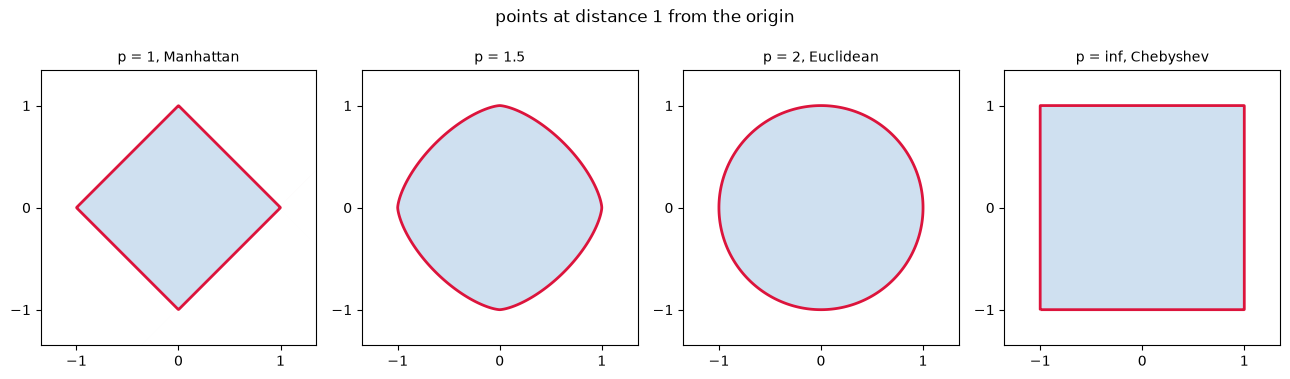

In [3]:
grid = np.linspace(-1.35, 1.35, 600)
gx, gy = np.meshgrid(grid, grid)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, (p, label) in zip(axes, [(1, "p = 1, Manhattan"), (1.5, "p = 1.5"),
                                 (2, "p = 2, Euclidean"), (np.inf, "p = inf, Chebyshev")]):
    if np.isinf(p):
        distance = np.maximum(np.abs(gx), np.abs(gy))
    else:
        distance = (np.abs(gx) ** p + np.abs(gy) ** p) ** (1 / p)
    ax.contourf(gx, gy, distance, levels=[0, 1], colors=["#cfe0f0"])
    ax.contour(gx, gy, distance, levels=[1], colors=["crimson"], linewidths=2)
    ax.set_title(label, fontsize=10)
    ax.set_aspect("equal"), ax.set_xticks([-1, 0, 1]), ax.set_yticks([-1, 0, 1])
fig.suptitle("points at distance 1 from the origin", y=1.04)
fig.tight_layout()
plt.show()

## Scaling decides everything

Distance adds up contributions from every feature, so a feature measured in bigger units counts for
more — purely because of its units, not because it matters more.

`proline` runs to 1680 and `nonflavanoid_phenols` to 0.66. Euclidean distance on the raw numbers is
very nearly the distance in `proline` alone.

Everything below uses the same split: 80/20, stratified so the three cultivars keep their
proportions in both halves.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=7, stratify=y)

print(f"train {len(y_train)} bottles {np.bincount(y_train)}, "
      f"test {len(y_test)} bottles {np.bincount(y_test)}\n")

print(f"{'features':<18}{'train':>9}{'test':>9}")
for label, model in (("raw", KNeighborsClassifier(5)),
                     ("standardised", make_pipeline(StandardScaler(), KNeighborsClassifier(5)))):
    model.fit(X_train, y_train)
    print(f"{label:<18}{model.score(X_train, y_train):>9.3f}{model.score(X_test, y_test):>9.3f}")

train 142 bottles [47 57 38], test 36 bottles [12 14 10]

features              train     test
raw                   0.803    0.722
standardised          0.972    1.000


From 0.722 to 1.000 for three lines of arithmetic that change nothing about the algorithm. No
choice of `k` below will come close to mattering this much.

Note also how the scaler is applied. It is inside a **pipeline**, so the mean and standard
deviation are computed on the training fold only and then applied to the test fold. Fitting the
scaler on all the data before splitting leaks information from the test set into training — a
quiet, common, and completely invisible mistake.

## Choosing k

`k = 1` classifies by the single closest bottle; large `k` averages over a wide neighbourhood.
Small `k` means high variance, large `k` means high bias, and the honest way to choose is
cross-validation **on the training set**.

In [5]:
folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
k_values = [1, 3, 5, 9, 15, 25, 35, 51]

print(f"{'k':>4}{'train':>9}{'CV mean':>10}{'CV std':>9}{'test':>9}")
for k in k_values:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(k))
    scores = cross_val_score(pipe, X_train, y_train, cv=folds)
    pipe.fit(X_train, y_train)
    print(f"{k:>4}{pipe.score(X_train, y_train):>9.3f}{scores.mean():>10.3f}"
          f"{scores.std():>9.3f}{pipe.score(X_test, y_test):>9.3f}")

   k    train   CV mean   CV std     test
   1    1.000     0.958    0.047    0.972
   3    0.965     0.950    0.056    0.972
   5    0.972     0.964    0.048    1.000
   9    0.979     0.971    0.035    1.000
  15    0.979     0.964    0.066    0.944
  25    0.979     0.971    0.047    0.972
  35    0.979     0.964    0.036    1.000
  51    0.944     0.936    0.081    1.000


Read the first row before anything else. **`k = 1` scores exactly 1.000 on the training set**, and
it always will — the nearest neighbour of a training point is itself. That perfect score measures
nothing at all, and it is the cleanest example of overfitting in the course.

Now read the rest, and notice that it is mostly noise. The CV standard deviations are 3 to 8
percentage points, which is larger than the gaps between the values of `k`. The test column bounces
between 0.944 and 1.000 without a pattern — unsurprising, since it has 36 entries, so a single
bottle is worth 2.8%.

On this evidence you cannot rank `k` at all. The fix is not a bigger model but more measurements.

In [6]:
repeats = 20
means = {k: [] for k in k_values}
for seed in range(repeats):
    folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)
    for k in k_values:
        pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(k))
        means[k].append(cross_val_score(pipe, X_train, y_train, cv=folds).mean())

averaged = np.array([np.mean(means[k]) for k in k_values])
spread = np.array([np.std(means[k]) for k in k_values])

print(f"10-fold CV repeated over {repeats} shuffles\n")
print(f"{'k':>4}{'mean':>9}{'std of the mean':>18}")
for k, m, s in zip(k_values, averaged, spread):
    print(f"{k:>4}{m:>9.4f}{s:>18.4f}")
print(f"\nbest k: {k_values[averaged.argmax()]}")

10-fold CV repeated over 20 shuffles

   k     mean   std of the mean
   1   0.9449            0.0057
   3   0.9571            0.0067
   5   0.9620            0.0045
   9   0.9688            0.0075
  15   0.9650            0.0050
  25   0.9740            0.0039
  35   0.9678            0.0068
  51   0.9430            0.0043

best k: 25


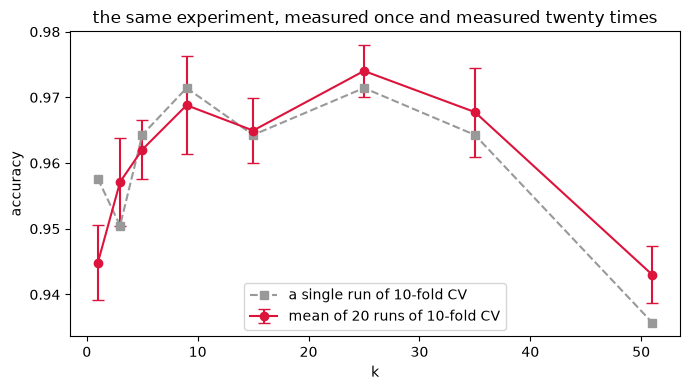

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(k_values, averaged, yerr=spread, marker="o", color="crimson",
            capsize=4, label=f"mean of {repeats} runs of 10-fold CV")
single = []
folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
for k in k_values:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(k))
    single.append(cross_val_score(pipe, X_train, y_train, cv=folds).mean())
ax.plot(k_values, single, marker="s", color="0.6", ls="--", label="a single run of 10-fold CV")
ax.set_xlabel("k"), ax.set_ylabel("accuracy"), ax.legend()
ax.set_title("the same experiment, measured once and measured twenty times")
fig.tight_layout()
plt.show()

The grey line is what one cross-validation run told us: a jagged mess with no clear message. The red
line is the same quantity measured twenty times, and now the shape is obvious — rising from `k = 1`,
peaking in the twenties, falling away by `k = 51`. Error bars under half a percentage point.

Nothing about the model changed. Only how many times it was measured.

**The rule this section exists to teach:** choose `k` from the red line, then touch the test set
once. Choosing `k` by test accuracy and then reporting that accuracy is reporting the best of eight
tries on 36 examples, which is a different and much smaller claim than it appears to be.

### When k earns its keep

On clean wine data the choice of `k` barely matters. Add thirty columns of pure noise and it
matters a great deal, because averaging over more neighbours is what cancels noise out.

In [8]:
X_noisy = np.c_[X, rng.normal(size=(len(X), 30))]
Xn_train, Xn_test, yn_train, yn_test = train_test_split(
    X_noisy, y, test_size=0.2, random_state=7, stratify=y)

folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
print("13 real features + 30 of pure noise\n")
print(f"{'k':>4}{'train':>9}{'CV mean':>10}{'CV std':>9}{'test':>9}")
for k in k_values:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(k))
    scores = cross_val_score(pipe, Xn_train, yn_train, cv=folds)
    pipe.fit(Xn_train, yn_train)
    print(f"{k:>4}{pipe.score(Xn_train, yn_train):>9.3f}{scores.mean():>10.3f}"
          f"{scores.std():>9.3f}{pipe.score(Xn_test, yn_test):>9.3f}")

13 real features + 30 of pure noise

   k    train   CV mean   CV std     test
   1    1.000     0.759    0.134    0.833
   3    0.915     0.843    0.110    0.861
   5    0.937     0.866    0.060    0.917
   9    0.930     0.908    0.064    0.917
  15    0.937     0.915    0.043    0.972
  25    0.937     0.915    0.063    0.917
  35    0.937     0.922    0.059    0.944
  51    0.937     0.915    0.054    0.944


`k = 1` falls to 0.759 while `k = 35` holds 0.922. The noise is what `k` is defending against, and
with none of it around there was nothing to defend.

## Reading the mistakes

Accuracy is one number covering every class. The **confusion matrix** is the same information
before it was flattened: rows are the true cultivar, columns the predicted one, so the diagonal is
what went right and every other cell names a specific mistake.

The scaled model makes no mistakes, so the unscaled one is the instructive half.

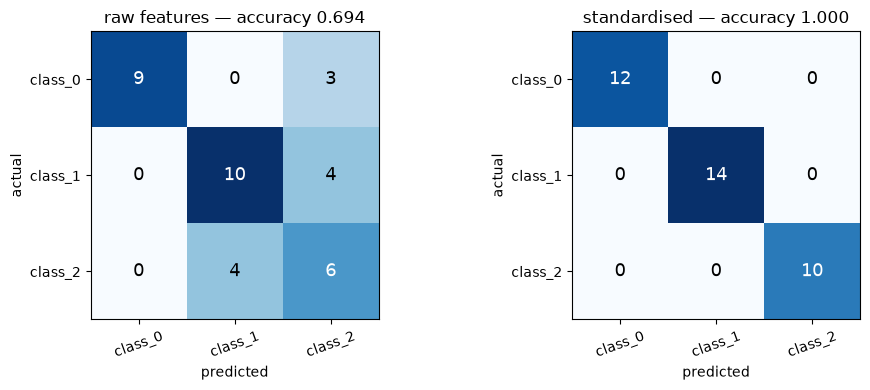

              precision    recall  f1-score   support

     class_0      1.000     0.750     0.857        12
     class_1      0.714     0.714     0.714        14
     class_2      0.462     0.600     0.522        10

    accuracy                          0.694        36
   macro avg      0.725     0.688     0.698        36
weighted avg      0.739     0.694     0.708        36



In [9]:
scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(9)).fit(X_train, y_train)
unscaled = KNeighborsClassifier(9).fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (label, model) in zip(axes, (("raw features", unscaled), ("standardised", scaled))):
    prediction = model.predict(X_test)
    matrix = confusion_matrix(y_test, prediction)
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=matrix.max())
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(j, i, matrix[i, j], ha="center", va="center",
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black", fontsize=13)
    ax.set_xticks(range(3), wine.target_names, rotation=20)
    ax.set_yticks(range(3), wine.target_names)
    ax.set_xlabel("predicted"), ax.set_ylabel("actual")
    ax.set_title(f"{label} — accuracy {(prediction == y_test).mean():.3f}")
fig.tight_layout()
plt.show()

print(classification_report(y_test, unscaled.predict(X_test),
                            target_names=wine.target_names, digits=3, zero_division=0))

The raw model's failure has a shape. `class_0` is never predicted wrongly when predicted at all —
precision 1.000 — but a quarter of real `class_0` bottles are missed, so its recall is 0.750.
`class_2` is the mirror image: recall 0.600 but precision 0.462, meaning more than half the bottles
it calls `class_2` are something else. One accuracy figure of 0.694 says none of that.

    Precision = TP / (TP + FP)      of the ones flagged, how many were right
    Recall    = TP / (TP + FN)      of the ones there were, how many were found
    F1        = 2PR / (P + R)

## When accuracy lies outright

The worst case for accuracy is a rare class. Here is the same data reshaped into "is this bottle
`class_2`?", with `class_2` down-sampled so it is about 9% of the data — the shape of a fraud
detector, a disease screen, or a defect test.

In [10]:
positive, negative = np.where(y == 2)[0], np.where(y != 2)[0]
keep = np.random.default_rng(3).choice(positive, 12, replace=False)
subset = np.concatenate([negative, keep])
X_rare, y_rare = X[subset], (y[subset] == 2).astype(int)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_rare, y_rare, test_size=0.4, random_state=2, stratify=y_rare)
print(f"{len(y_rare)} bottles, {y_rare.sum()} positive ({y_rare.mean():.1%})")
print(f"test set: {len(yr_test)} bottles, {yr_test.sum()} positive\n")

majority = np.full(len(yr_test), np.bincount(yr_train).argmax())
predictions = {
    'always predict "no"': majority,
    "kNN, raw features": KNeighborsClassifier(5).fit(Xr_train, yr_train).predict(Xr_test),
    "kNN, standardised": make_pipeline(StandardScaler(), KNeighborsClassifier(5))
                         .fit(Xr_train, yr_train).predict(Xr_test),
}

print(f"{'model':<22}{'accuracy':>10}{'precision':>11}{'recall':>9}{'F1':>7}   confusion")
for label, prediction in predictions.items():
    p, r, f1, _ = precision_recall_fscore_support(yr_test, prediction, average="binary",
                                                  zero_division=0)
    print(f"{label:<22}{(prediction == yr_test).mean():>10.3f}{p:>11.3f}{r:>9.3f}{f1:>7.3f}"
          f"   {confusion_matrix(yr_test, prediction).tolist()}")

142 bottles, 12 positive (8.5%)
test set: 57 bottles, 5 positive

model                   accuracy  precision   recall     F1   confusion
always predict "no"        0.912      0.000    0.000  0.000   [[52, 0], [5, 0]]
kNN, raw features          0.912      0.000    0.000  0.000   [[52, 0], [5, 0]]
kNN, standardised          0.965      0.800    0.800  0.800   [[51, 1], [1, 4]]


The first two rows have **identical accuracy**, and both are worthless: neither finds a single
positive case. A model that has learned nothing at all and a model that has learned nothing useful
are indistinguishable by accuracy, and separated instantly by recall.

Whenever one class is rare, quote precision and recall, or quote the confusion matrix and let the
reader work it out. Accuracy on imbalanced data is not a weak measurement — it is a misleading one.

## kd-trees: neighbours without measuring everything

Every prediction so far measured the distance to all 142 training bottles. That is fine here and
hopeless for millions of points, so this section builds the standard fix from scratch: a
**kd-tree**. The library has one (`KNeighborsClassifier(algorithm="kd_tree")`), but it hides
exactly the part worth seeing, which is which points it never looks at.

The cost to watch is the number of **distances measured**, not seconds. A tree written in plain
Python against brute force in vectorised numpy would compare two languages, not two algorithms.

Three pieces:

- **Build.** Take the feature with the widest spread, put the median point along it in the node,
  everything below it in the left subtree and everything above it in the right, and recurse. The
  median keeps the tree balanced, about `log₂ N` levels deep.
- **Search.** Keep the best `k` found so far in a max-heap, so the worst of them is on top. Walk
  into the query's own side of each split first.
- **Prune.** Every point on the far side of a split differs from the query by at least the
  distance to the splitting plane in that one feature, and a Minkowski distance is never smaller
  than one feature's difference. So when the plane is farther away than the current `k`-th best,
  the whole far subtree is skipped, unmeasured.

In [4]:
import heapq


def minkowski(rows, q, p=2):
    """Minkowski distance from q to each row (or to a single row)."""
    return np.sum(np.abs(rows - q) ** p, axis=-1) ** (1 / p)


class KDTree:
    """k-nearest-neighbour search with a kd-tree, under the Minkowski distance (p >= 1)."""

    def __init__(self, X, p=2):
        self.X, self.p = np.asarray(X, dtype=float), p
        # node n stores one training point, the feature it splits on, and its two children
        self.point, self.axis, self.left, self.right = [], [], [], []
        self.root = self._build(np.arange(len(self.X)))

    def _build(self, idx):
        if len(idx) == 0:
            return -1                                        # no node
        spread = self.X[idx].max(axis=0) - self.X[idx].min(axis=0)
        axis = int(spread.argmax())                          # split the widest feature...
        idx = idx[np.argsort(self.X[idx, axis], kind="stable")]
        mid = len(idx) // 2                                  # ...at its median
        node = len(self.point)
        self.point.append(int(idx[mid])), self.axis.append(axis)
        self.left.append(-1), self.right.append(-1)
        self.left[node] = self._build(idx[:mid])             # values <= the median
        self.right[node] = self._build(idx[mid + 1:])        # values >= it
        return node

    def query(self, q, k, trace=None):
        """The k nearest training points to q as (distance, index) pairs, nearest first."""
        self.computed = 0                                    # distances actually measured
        best = []    # the k best so far, as a max-heap of (-distance, -index)
        self._search(self.root, np.asarray(q, dtype=float), k, best, trace)
        return sorted((-d, -i) for d, i in best)

    def _search(self, node, q, k, best, trace):
        if node < 0:
            return
        i, axis = self.point[node], self.axis[node]
        d = minkowski(self.X[i], q, self.p)
        self.computed += 1
        heapq.heappush(best, (-d, -i))
        if len(best) > k:
            heapq.heappop(best)                              # drop the worst candidate
        if trace is not None:
            trace.append(("visit", i, d, -best[0][0]))

        diff = q[axis] - self.X[i, axis]                     # the query's distance to the split
        near, far = ((self.left[node], self.right[node]) if diff <= 0
                     else (self.right[node], self.left[node]))
        self._search(near, q, k, best, trace)                # the query's own side first
        # The far side can only help while the plane is within the current k-th best distance.
        # "<=" rather than "<": a far point at exactly that distance but with a smaller index
        # would win the tie in brute force, so it must not be pruned.
        if len(best) < k or abs(diff) <= -best[0][0]:
            self._search(far, q, k, best, trace)
        elif trace is not None:
            trace.append(("prune", i, abs(diff), -best[0][0]))


def brute_force(X, q, k, p=2):
    """The reference: measure everything, sort by distance, then by index."""
    d = minkowski(X, q, p)
    order = np.lexsort((np.arange(len(X)), d))[:k]
    return [(d[i], int(i)) for i in order]

### Six points by hand

The same example as the README, small enough to follow every step. The tree is printed with each
node's split; then a query traces which nodes it visits and which subtree it never enters.

In [5]:
corners = np.array([[2, 3], [5, 4], [9, 6], [4, 7], [8, 1], [7, 2]], dtype=float)
names = "ABCDEF"
small = KDTree(corners)


def show(node, depth=0, side="root"):
    if node < 0:
        return
    i, axis = small.point[node], small.axis[node]
    leaf = small.left[node] < 0 and small.right[node] < 0
    split = "a leaf" if leaf else f"splits on {'xy'[axis]} = {corners[i, axis]:g}"
    print(f"{'    ' * depth}{side:>5}: {names[i]}({corners[i, 0]:g}, {corners[i, 1]:g})  {split}")
    show(small.left[node], depth + 1, "left")
    show(small.right[node], depth + 1, "right")


show(small.root)

trace = []
nearest = small.query([3, 4], k=1, trace=trace)
print("\nquery (3, 4), k = 1:")
for kind, i, value, worst in trace:
    if kind == "visit":
        print(f"  visit {names[i]}: distance {value:.2f}   (best so far {worst:.2f})")
    else:
        print(f"  skip everything on the far side of {names[i]}: the split is {value:.2f} away, "
              f"more than {worst:.2f}")
print(f"nearest: {names[nearest[0][1]]}, after {small.computed} of {len(corners)} distances")

 root: F(7, 2)  splits on x = 7
     left: B(5, 4)  splits on y = 4
         left: A(2, 3)  a leaf
        right: D(4, 7)  a leaf
    right: C(9, 6)  splits on y = 6
         left: E(8, 1)  a leaf

query (3, 4), k = 1:
  visit F: distance 4.47   (best so far 4.47)
  visit B: distance 2.00   (best so far 2.00)
  visit A: distance 1.41   (best so far 1.41)
  visit D: distance 3.16   (best so far 1.41)
  skip everything on the far side of F: the split is 4.00 away, more than 1.41
nearest: A, after 4 of 6 distances


### First it has to be right

A fast search that returns different neighbours is a bug, so before counting anything, compare it
with brute force: the same `(distance, index)` lists, for every test bottle and every `k` from 1 to
20, on the standardised data.

In [13]:
scaler = StandardScaler().fit(X_train)
Z_train, Z_test = scaler.transform(X_train), scaler.transform(X_test)
tree = KDTree(Z_train)

mismatches, measured = 0, []
for k in range(1, 21):
    for q in Z_test:
        mismatches += tree.query(q, k) != brute_force(Z_train, q, k)
        measured.append(tree.computed)

print(f"{len(measured)} queries: {mismatches} differ from brute force")
print(f"distances measured per query: {np.mean(measured):.0f} of {len(Z_train)} on average "
      f"({np.mean(measured) / len(Z_train):.0%})")

720 queries: 0 differ from brute force
distances measured per query: 136 of 142 on average (96%)


### What it skips

The pruning is easiest to see in two dimensions. Three hundred random points, the splits drawn as
the tree made them, and one query asking for its five nearest neighbours.

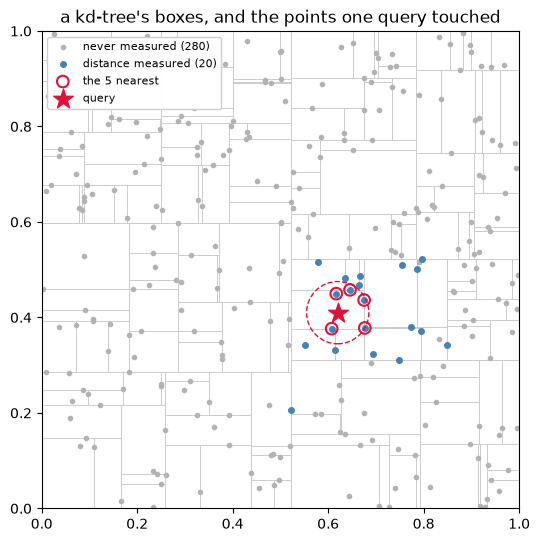

In [14]:
points = np.random.default_rng(4).random((300, 2))
plane = KDTree(points)
query, k = np.array([0.62, 0.41]), 5
trace = []
found = plane.query(query, k, trace=trace)
visited = sorted({i for kind, i, *_ in trace if kind == "visit"})
never = np.setdiff1d(np.arange(len(points)), visited)

fig, ax = plt.subplots(figsize=(6.2, 6.2))


def draw(node, x0, x1, y0, y1):
    if node < 0 or (plane.left[node] < 0 and plane.right[node] < 0):
        return                                               # a leaf splits nothing
    i, axis = plane.point[node], plane.axis[node]
    v = points[i, axis]
    if axis == 0:
        ax.plot([v, v], [y0, y1], color="0.8", lw=0.7, zorder=0)
        draw(plane.left[node], x0, v, y0, y1), draw(plane.right[node], v, x1, y0, y1)
    else:
        ax.plot([x0, x1], [v, v], color="0.8", lw=0.7, zorder=0)
        draw(plane.left[node], x0, x1, y0, v), draw(plane.right[node], x0, x1, v, y1)


draw(plane.root, 0, 1, 0, 1)
ax.scatter(*points[never].T, s=9, color="0.7", label=f"never measured ({len(never)})")
ax.scatter(*points[visited].T, s=16, color="steelblue", label=f"distance measured ({len(visited)})")
ax.scatter(*points[[i for _, i in found]].T, s=70, facecolor="none", edgecolor="crimson", lw=1.5,
           label=f"the {k} nearest")
ax.scatter(*query, marker="*", s=220, color="crimson", zorder=3, label="query")
ax.add_patch(plt.Circle(query, found[-1][0], fill=False, ls="--", color="crimson"))
ax.set_xlim(0, 1), ax.set_ylim(0, 1), ax.set_aspect("equal")
ax.set_title("a kd-tree's boxes, and the points one query touched")
ax.legend(loc="upper left", fontsize=8, framealpha=0.95)
plt.show()

The dashed circle is the distance to the fifth nearest point. Any box that does not reach into it
was skipped whole. Now the two questions that decide whether a kd-tree is worth having: how does
the cost grow with the number of points, and with the number of features?

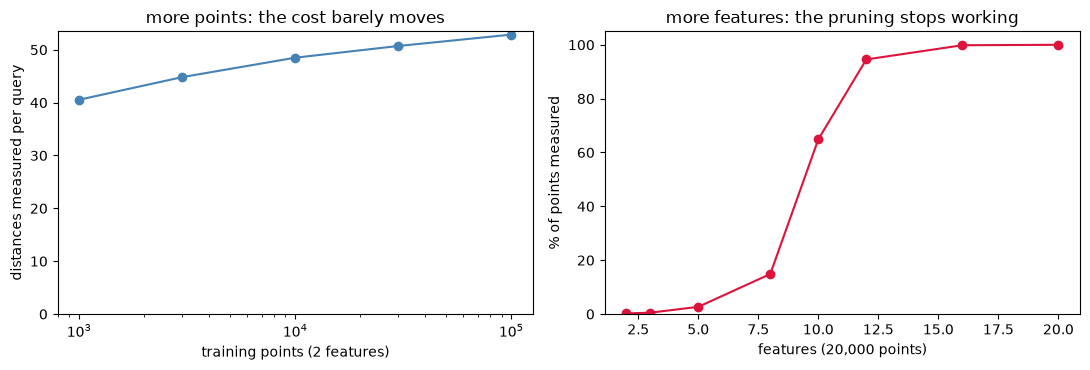

    points   measured per query
     1,000                 40.6
     3,000                 44.8
    10,000                 48.5
    30,000                 50.7
   100,000                 52.9

  features   share measured
         2             0.2%
         3             0.5%
         5             2.7%
         8            14.9%
        10            64.9%
        12            94.6%
        16            99.8%
        20           100.0%


In [15]:
sizes = [1_000, 3_000, 10_000, 30_000, 100_000]
cost = []
for n in sizes:
    cloud = KDTree(np.random.default_rng(0).random((n, 2)))
    probes = np.random.default_rng(1).random((200, 2))
    cost.append(np.mean([(cloud.query(q, 10), cloud.computed)[1] for q in probes]))

dims = [2, 3, 5, 8, 10, 12, 16, 20]
share = []
for d in dims:
    cloud = KDTree(np.random.default_rng(0).random((20_000, d)))
    probes = np.random.default_rng(1).random((40, d))
    share.append(np.mean([(cloud.query(q, 10), cloud.computed)[1] for q in probes]) / 20_000)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(sizes, cost, marker="o", color="steelblue")
ax1.set_xscale("log"), ax1.set_ylim(0, None)
ax1.set_xlabel("training points (2 features)"), ax1.set_ylabel("distances measured per query")
ax1.set_title("more points: the cost barely moves")
ax2.plot(dims, np.array(share) * 100, marker="o", color="crimson")
ax2.set_xlabel("features (20,000 points)"), ax2.set_ylabel("% of points measured")
ax2.set_ylim(0, 105), ax2.set_title("more features: the pruning stops working")
fig.tight_layout()
plt.show()

print(f"{'points':>10}{'measured per query':>21}")
for n, c in zip(sizes, cost):
    print(f"{n:>10,}{c:>21.1f}")
print(f"\n{'features':>10}{'share measured':>17}")
for d, s in zip(dims, share):
    print(f"{d:>10}{s:>17.1%}")

**More points:** a hundred times as many, 1,000 to 100,000, and a query goes from 41 measured
distances to 53, while brute force goes from 1,000 to 100,000. That is the `log N` growth a
balanced tree promises.

**More features:** the same 20,000 points, and the share that has to be measured goes 0.2% in two
dimensions, 15% at eight, 65% at ten, 95% at twelve, and everything from sixteen on. Pruning needs a
splitting plane farther away than the current `k`-th neighbour, and in many dimensions that
neighbour is far away in *every* direction, which is the next section's subject. A rough rule:
a kd-tree only pays while `N` is much larger than `2^d`, since it takes about that many points just
to split every feature once.

The wine data has thirteen features and 142 training bottles, and the tree measured **96%** of
them per query: correct, and of no use at all here. Brute force is the right choice for this
notebook, and the tree is the right choice for many points in few dimensions. Knowing which case
you are in is the whole skill.

## The curse of dimensionality

kNN depends on "near" being meaningful. In enough dimensions it stops being so, and the collapse is
easy to watch: keep the thirteen real measurements and bury them in columns of pure noise.

13 real +   0 noise features: test accuracy 1.000
13 real +   5 noise features: test accuracy 0.917
13 real +  13 noise features: test accuracy 0.861
13 real +  50 noise features: test accuracy 0.833
13 real + 100 noise features: test accuracy 0.806
13 real + 200 noise features: test accuracy 0.778
13 real + 500 noise features: test accuracy 0.472


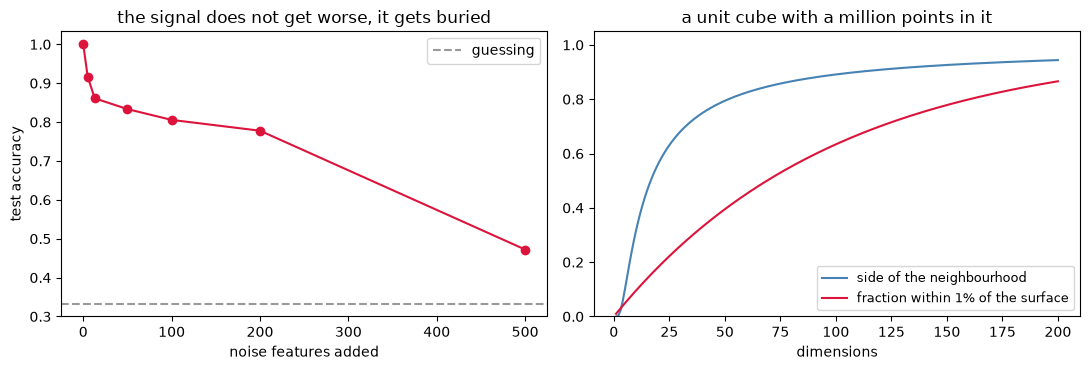


  dimensions   neighbourhood side   within 1% of surface
           2                0.003                  0.020
           3                0.022                  0.030
          10                0.316                  0.096
         100                0.891                  0.634
         200                0.944                  0.866


In [16]:
counts = [0, 5, 13, 50, 100, 200, 500]
accuracies = []
noise_rng = np.random.default_rng(0)
for extra in counts:
    data = np.c_[X, noise_rng.normal(size=(len(X), extra))] if extra else X
    a, b, c, d = train_test_split(data, y, test_size=0.2, random_state=7, stratify=y)
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(5)).fit(a, c)
    accuracies.append(model.score(b, d))
    print(f"13 real + {extra:>3} noise features: test accuracy {accuracies[-1]:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(counts, accuracies, marker="o", color="crimson")
ax1.axhline(1 / 3, color="0.6", ls="--", label="guessing")
ax1.set_xlabel("noise features added"), ax1.set_ylabel("test accuracy")
ax1.set_title("the signal does not get worse, it gets buried"), ax1.legend()

dims = np.arange(1, 201)
ax2.plot(dims, (10 / 1e6) ** (1 / dims), color="steelblue", label="side of the neighbourhood")
ax2.plot(dims, 1 - 0.99**dims, color="crimson", label="fraction within 1% of the surface")
ax2.set_xlabel("dimensions"), ax2.set_ylim(0, 1.05), ax2.legend(fontsize=9)
ax2.set_title("a unit cube with a million points in it")
fig.tight_layout()
plt.show()

print(f"\n{'dimensions':>12}{'neighbourhood side':>21}{'within 1% of surface':>23}")
for n in (2, 3, 10, 100, 200):
    print(f"{n:>12}{(10 / 1e6) ** (1 / n):>21.3f}{1 - 0.99**n:>23.3f}")

The blue curve is the side length of the smallest cube holding the 10 nearest of a million points.
In a hundred dimensions it spans **89%** of the range of every feature — those points are not
"near" by any reading of the word, and the label kNN copies from them is close to arbitrary.

The red curve says almost every point is within 1% of the boundary, so nearly everything is an edge
case with no neighbours on one side.

This is also why kd-trees stop helping. Their whole advantage is discarding a subtree because the
splitting plane is farther away than the current best neighbour — and once the nearest neighbour is
89% of the way across the cube, no plane is ever far enough, so nothing gets pruned. The kd-tree
section measured it: from twelve features on, the tree looked at nearly every point anyway.

## Where this leaves us

- **kNN has no training phase and no assumptions**, and on well-scaled wine data it classifies the
  test set perfectly. Use it as the baseline before anything more elaborate.
- **Preprocessing outweighed the algorithm.** Scaling moved accuracy 0.722 to 1.000; no value of
  `k` mattered nearly as much.
- **`k = 1` scores 1.000 on its own training set**, which is what a perfect training score is
  usually worth.
- **One measurement is not a measurement.** A single cross-validation run could not rank `k` at all;
  twenty runs made the curve obvious. Report a mean and a spread.
- **A kd-tree is a tool for few dimensions.** It found the nearest of 100,000 points after 53
  distances in two dimensions, and measured 96% of the wine data in thirteen.
- **Accuracy hides the interesting part**, and on imbalanced data it actively misleads. The
  confusion matrix costs one line and says what actually happened.